In [1]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully!")


Mounted at /content/drive
Google Drive mounted successfully!


In [2]:

from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/CSE499-Medical-AI")

folders = [
    "00_Project_Documents",
    "01_Dataset",
    "02_Notebooks",
    "03_Models",
    "04_Results",
    "05_Figures",
    "06_XAI",
    "07_Dashboard",
    "08_Reports",
    "09_Presentation"
]

print("PROJECT FOLDER VERIFICATION")
print("-" * 40)

all_found = True

for folder in folders:
    folder_path = PROJECT_ROOT / folder

    if folder_path.is_dir():
        print(f"[OK] {folder}")
    else:
        print(f"[MISSING] {folder}")
        all_found = False

print("-" * 40)

if all_found:
    print("SUCCESS: All 10 project folders verified!")
else:
    print("WARNING: Some folders are missing.")


PROJECT FOLDER VERIFICATION
----------------------------------------
[OK] 00_Project_Documents
[OK] 01_Dataset
[OK] 02_Notebooks
[OK] 03_Models
[OK] 04_Results
[OK] 05_Figures
[OK] 06_XAI
[OK] 07_Dashboard
[OK] 08_Reports
[OK] 09_Presentation
----------------------------------------
SUCCESS: All 10 project folders verified!


In [3]:


# Task: Verify Python, required libraries, and GPU availability

import sys
import importlib
import torch

# 1. Check the installed Python version
print("Python Version:", sys.version.split()[0])

# 2. Check the required Python libraries
libraries = {
    "NumPy": "numpy",
    "Pandas": "pandas",
    "Matplotlib": "matplotlib",
    "Scikit-learn": "sklearn",
    "PyTorch": "torch",
    "Torchvision": "torchvision",
    "Pillow": "PIL"
}

print("\nInstalled Libraries:")

for name, module_name in libraries.items():
    try:
        module = importlib.import_module(module_name)
        version = getattr(module, "__version__", "Installed")
        print(f"{name}: {version}")
    except Exception as error:
        print(f"{name}: ERROR - {error}")

# 3. Check whether a GPU is available
print("\nGPU Information:")

if torch.cuda.is_available():
    print("CUDA Available: Yes")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA Available: No")
    print("GPU: CPU runtime")

# 4. Confirm the environment check is complete
print("\nEnvironment verification completed.")


Python Version: 3.13.16

Installed Libraries:
NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
Scikit-learn: 1.6.1
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Pillow: 11.3.0

GPU Information:
CUDA Available: Yes
GPU: Tesla T4

Environment verification completed.


In [4]:


# Task: Verify Google Drive project folder access

from pathlib import Path

# 1. Define the existing project directory
PROJECT_ROOT = Path("/content/drive/MyDrive/CSE499-Medical-AI")

# 2. Check whether the project directory exists
if PROJECT_ROOT.is_dir():
    print("Project folder found.")
    print("Location:", PROJECT_ROOT)
else:
    print("ERROR: Project folder not found.")

# 3. Test file-writing permission
if PROJECT_ROOT.is_dir():
    test_file = PROJECT_ROOT / "00_Project_Documents" / "setup_test.txt"

    try:
        test_file.write_text(
            "Medical-AI-CXR project setup verified.",
            encoding="utf-8"
        )

        saved_text = test_file.read_text(encoding="utf-8")

        print("\nFile Writing Test:")
        print("Saved content:", saved_text)
        print("Write permission: Working")

    except Exception as error:
        print("File writing failed:", error)


Project folder found.
Location: /content/drive/MyDrive/CSE499-Medical-AI

File Writing Test:
Saved content: Medical-AI-CXR project setup verified.
Write permission: Working


##Verify GPU connection

In [5]:


# Task: Verify GPU availability using PyTorch

import torch

# 1. Display the installed PyTorch version
print("PyTorch Version:", torch.__version__)

# 2. Check whether CUDA is available
print("CUDA Available:", torch.cuda.is_available())

# 3. Display GPU information
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Count:", torch.cuda.device_count())

    # Create a small tensor directly on the GPU
    test_tensor = torch.tensor([1.0, 2.0, 3.0], device="cuda")

    print("GPU Test Tensor:", test_tensor)
    print("GPU Test: Successful")
else:
    print("GPU not detected. Check the Colab runtime settings.")


PyTorch Version: 2.11.0+cu130
CUDA Available: True
GPU Name: Tesla T4
GPU Count: 1
GPU Test Tensor: tensor([1., 2., 3.], device='cuda:0')
GPU Test: Successful


In [6]:

# SERIAL 01 — STEP 9
# Project: Medical-AI-CXR
# Task: Reconnect and verify Google Drive access

from google.colab import drive
from pathlib import Path

# 1. Mount Google Drive if it is not already connected
drive.mount("/content/drive")

# 2. Define the existing project folder
PROJECT_ROOT = Path("/content/drive/MyDrive/CSE499-Medical-AI")

# 3. Verify access to the project directory
if PROJECT_ROOT.is_dir():
    print("Project Folder: Found")
    print("Project Path:", PROJECT_ROOT)
    print("Google Drive Access: Successful")
else:
    print("Project Folder: Not Found")
    print("Please check your Google Drive connection.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project Folder: Found
Project Path: /content/drive/MyDrive/CSE499-Medical-AI
Google Drive Access: Successful


##Save Environment Configuration

In [7]:

import sys
import json
import importlib.metadata
from pathlib import Path
import torch

project_root = Path("/content/drive/MyDrive/CSE499-Medical-AI")
config_file = project_root / "00_Project_Documents" / "environment_config.json"

packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scikit_learn": "scikit-learn",
    "torch": "torch",
    "torchvision": "torchvision",
    "pillow": "Pillow"
}

library_versions = {}

for name, package in packages.items():
    library_versions[name] = importlib.metadata.version(package)

environment = {
    "python_version": sys.version.split()[0],
    "libraries": library_versions,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
}

with open(config_file, "w", encoding="utf-8") as file:
    json.dump(environment, file, indent=4)

with open(config_file, "r", encoding="utf-8") as file:
    saved_environment = json.load(file)

print("Configuration saved:", config_file)
print("Python:", saved_environment["python_version"])
print("PyTorch:", saved_environment["libraries"]["torch"])
print("GPU:", saved_environment["gpu_name"])


Configuration saved: /content/drive/MyDrive/CSE499-Medical-AI/00_Project_Documents/environment_config.json
Python: 3.13.16
PyTorch: 2.11.0+cu130
GPU: Tesla T4


##Check our dataset folder

In [8]:

from pathlib import Path

# This is the folder where I will keep my chest X-ray dataset
dataset_path = Path("/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset")

# Check if the dataset folder exists
if dataset_path.exists():
    print("Dataset folder found.")
    print("Location:", dataset_path)

    # Show the files and folders that are already inside it
    items = sorted(dataset_path.iterdir())

    if items:
        print("\nExisting files and folders:")

        for item in items:
            if item.is_dir():
                print("Folder:", item.name)
            else:
                print("File:", item.name)
    else:
        print("The dataset folder is empty.")

else:
    print("Dataset folder not found.")


Dataset folder found.
Location: /content/drive/MyDrive/CSE499-Medical-AI/01_Dataset

Existing files and folders:
Folder: CheXpert


##Inspect the CheXpert folder

In [9]:

from pathlib import Path

# Set the location of my CheXpert dataset
chexpert_path = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert"
)

# Check the dataset directory before reading its contents
if chexpert_path.is_dir():
    print("CheXpert folder found.")

    # List the files and folders inside CheXpert
    items = sorted(chexpert_path.iterdir())

    if items:
        print("\nContents:")

        for item in items:
            if item.is_dir():
                print("Folder:", item.name)
            else:
                print("File:", item.name)
    else:
        print("CheXpert folder is empty.")
else:
    print("CheXpert folder not found.")


CheXpert folder found.

Contents:
Folder: CheXpert-v1.0-small


##Verify CheXpert dataset files

In [10]:

from pathlib import Path

# Set the location of my CheXpert dataset
dataset_path = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small"
)

# Check the files and folders inside the dataset
if dataset_path.is_dir():
    print("CheXpert dataset found.")

    items = sorted(dataset_path.iterdir())

    print("\nDataset contents:")

    for item in items:
        if item.is_dir():
            print("Folder:", item.name)
        else:
            print("File:", item.name)

    # Check the main files and folders needed for training
    required_items = [
        "train",
        "valid",
        "train.csv",
        "valid.csv"
    ]

    print("\nRequired dataset items:")

    for name in required_items:
        if (dataset_path / name).exists():
            print(f"{name}: Found")
        else:
            print(f"{name}: Missing")

else:
    print("Dataset folder not found.")


CheXpert dataset found.

Dataset contents:
Folder: train
File: train.csv
Folder: valid
File: valid.csv

Required dataset items:
train: Found
valid: Found
train.csv: Found
valid.csv: Found


##Read training and validation CSV files

In [11]:

import pandas as pd
from pathlib import Path

# Set the location of my CheXpert dataset
dataset_path = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert/CheXpert-v1.0-small"
)

# Load the training and validation CSV files
train_df = pd.read_csv(dataset_path / "train.csv")
valid_df = pd.read_csv(dataset_path / "valid.csv")

# Check the number of rows and columns in each dataset
print("Training Dataset:")
print("Rows:", train_df.shape[0])
print("Columns:", train_df.shape[1])

print("\nValidation Dataset:")
print("Rows:", valid_df.shape[0])
print("Columns:", valid_df.shape[1])

# Display the column names to understand the available information
print("\nColumn Names:")
print(train_df.columns.tolist())

# Preview the first three training records
print("\nFirst 3 Training Records:")
display(train_df.head(3))


Training Dataset:
Rows: 223414
Columns: 19

Validation Dataset:
Rows: 234
Columns: 19

Column Names:
['Path', 'Sex', 'Age', 'Frontal/Lateral', 'AP/PA', 'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']

First 3 Training Records:


,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices
0,CheXpert-v1.0-small/train/patient00001/study1/...,Female,68,Frontal,AP,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0
1,CheXpert-v1.0-small/train/patient00002/study2/...,Female,87,Frontal,AP,NaN,NaN,-1.0,1.0,NaN,-1.0,-1.0,NaN,-1.0,NaN,-1.0,NaN,1.0,NaN
2,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Frontal,AP,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN


##Analyze medical labels

In [12]:

import pandas as pd

# These are the 14 medical observations in the CheXpert dataset
label_columns = train_df.columns[5:]

# Count the different label values for each observation
label_summary = pd.DataFrame({
    "Positive (1)": (train_df[label_columns] == 1).sum(),
    "Negative (0)": (train_df[label_columns] == 0).sum(),
    "Uncertain (-1)": (train_df[label_columns] == -1).sum(),
    "Missing (NaN)": train_df[label_columns].isna().sum()
})

# Display the summary for all medical observations
print("Training Dataset Label Summary:")
display(label_summary)

# Check the total number of uncertain labels
total_uncertain = label_summary["Uncertain (-1)"].sum()

print("Total uncertain label entries:", total_uncertain)


Training Dataset Label Summary:


,Positive (1),Negative (0),Uncertain (-1),Missing (NaN)
No Finding,22381,0,0,201033
Enlarged Cardiomediastinum,10798,21638,12403,178575
Cardiomegaly,27000,11116,8087,177211
Lung Opacity,105581,6599,5598,105636
Lung Lesion,9186,1270,1488,211470
Edema,52246,20726,12984,137458
Consolidation,14783,28097,27742,152792
Pneumonia,6039,2799,18770,195806
Atelectasis,33376,1328,33739,154971
Pneumothorax,19448,56341,3145,144480


Total uncertain label entries: 139958


Some important findings from your results:
- Pleural Effusion: 86,187 positive labels.
- Lung Opacity: 105,581 positive labels.
- Consolidation: 27,742 uncertain labels.
- Atelectasis: 33,739 uncertain labels.
- Pneumonia: 18,770 uncertain labels.
This tells us that uncertain labels are an important challenge in our dataset. Later, we will compare suitable methods for handling them rather than automatically treating every uncertain label as positive or negative.

## Visualize the label distribution

Create a graph showing the number of positive, negative, uncertain, and missing labels for each medical observation.

This will help us understand the dataset visually and identify class imbalance.

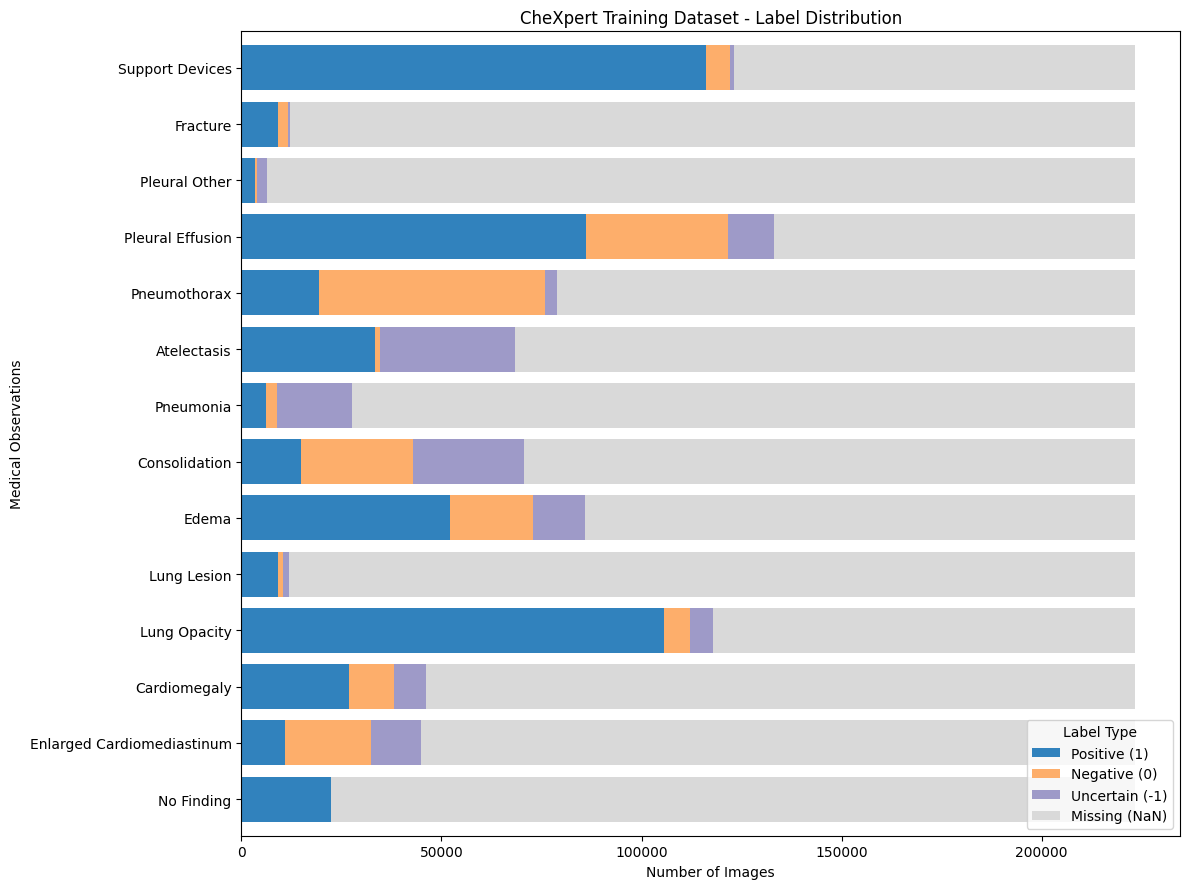

In [13]:

import matplotlib.pyplot as plt

# Select the label counts from the previous step
plot_data = label_summary[
    ["Positive (1)", "Negative (0)", "Uncertain (-1)", "Missing (NaN)"]
]

# Create a horizontal stacked bar chart
ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 9),
    colormap="tab20c",
    width=0.8
)

# Add chart labels and title
plt.title("CheXpert Training Dataset - Label Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Medical Observations")
plt.legend(title="Label Type", loc="lower right")

# Improve the layout
plt.tight_layout()
plt.show()


- Blue: Positive labels (1).
- Orange: Negative labels (0).
- Purple: Uncertain labels (-1).
- Gray: Missing labels (NaN).


The graph confirms that many observations have large numbers of missing labels. It also shows substantial uncertainty for Atelectasis and Consolidation.

##Save the label distribution graph

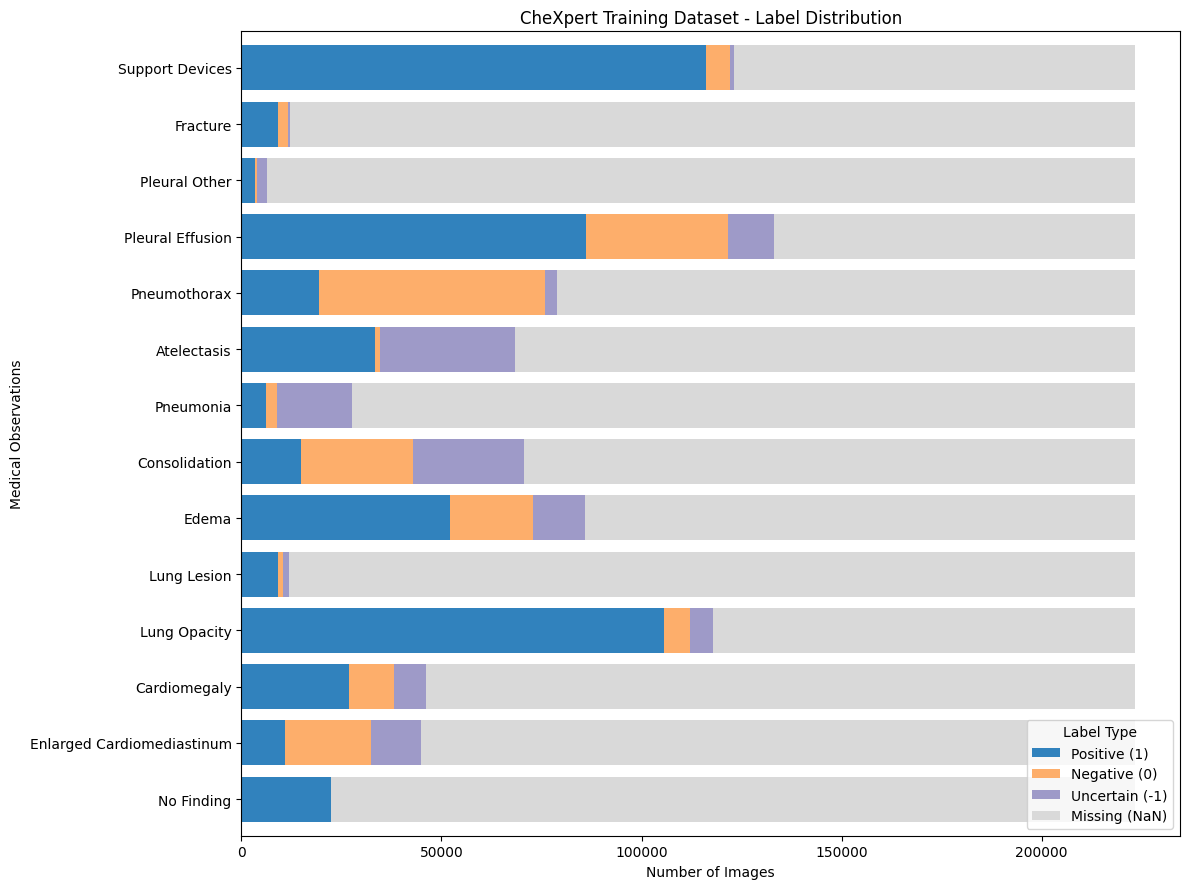

Graph saved: /content/drive/MyDrive/CSE499-Medical-AI/05_Figures/chexpert_label_distribution.png
File exists: True


In [14]:

import matplotlib.pyplot as plt
from pathlib import Path

# Set the folder where I want to save my graphs
figures_path = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/05_Figures"
)

# Select the label counts for visualization
plot_data = label_summary[
    ["Positive (1)", "Negative (0)", "Uncertain (-1)", "Missing (NaN)"]
]

# Create the label distribution chart
ax = plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 9),
    colormap="tab20c",
    width=0.8
)

# Add labels to make the graph easier to understand
plt.title("CheXpert Training Dataset - Label Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Medical Observations")
plt.legend(title="Label Type", loc="lower right")

plt.tight_layout()

# Save the graph in high resolution
figure_file = figures_path / "chexpert_label_distribution.png"
plt.savefig(figure_file, dpi=300, bbox_inches="tight")

plt.show()

print("Graph saved:", figure_file)
print("File exists:", figure_file.exists())


##Verify actual chest X-ray images

Check whether the image paths recorded in train.csv and valid.csv point to actual image files in Google Drive.

In [16]:

from pathlib import Path
from PIL import Image

# Locate the first training image using its CSV path
dataset_parent = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert"
)

image_path = dataset_parent / train_df["Path"].iloc[0]

print("Image:", image_path.name)

# Try opening the image to confirm that Python can read it
try:
    with Image.open(image_path) as image:
        image.load()
        print("Image opened successfully.")
        print("Image size:", image.size)
        print("Image format:", image.format)

except OSError as error:
    print("Image access failed:", error)


Image: view1_frontal.jpg
Image opened successfully.
Image size: (389, 320)
Image format: JPEG


#Display the first chest X-ray

Display the image to confirm that it can be decoded and visualized correctly

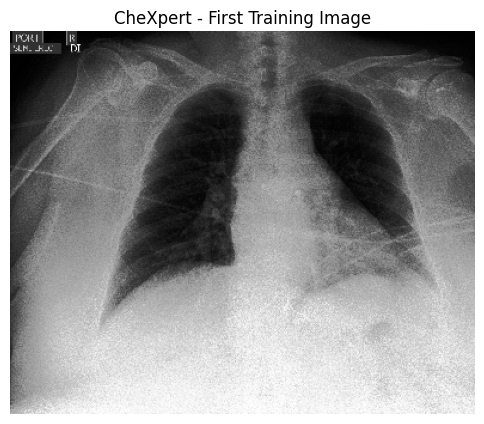

In [17]:

from PIL import Image
import matplotlib.pyplot as plt

# Open the first training image from the CheXpert dataset
image_path = dataset_parent / train_df["Path"].iloc[0]

with Image.open(image_path) as image:
    xray_image = image.convert("RGB")

# Display the X-ray image
plt.figure(figsize=(6, 6))
plt.imshow(xray_image)
plt.title("CheXpert - First Training Image")
plt.axis("off")
plt.show()


##Verify a validation image

Confirm that we can also load images from the CheXpert validation dataset.

We have tested a training image. Now we will test one validation image.

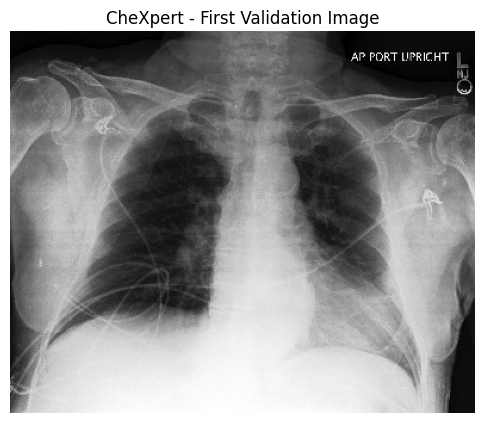

Image: view1_frontal.jpg
Image size: (390, 320)
Image format: None


In [18]:

from PIL import Image
import matplotlib.pyplot as plt

# Get the first image path from the validation CSV
validation_image_path = dataset_parent / valid_df["Path"].iloc[0]

# Open the image and prepare it for display
with Image.open(validation_image_path) as image:
    validation_image = image.copy()

# Display the validation X-ray
plt.figure(figsize=(6, 6))
plt.imshow(validation_image, cmap="gray")
plt.title("CheXpert - First Validation Image")
plt.axis("off")
plt.show()

# Show the image information
print("Image:", validation_image_path.name)
print("Image size:", validation_image.size)
print("Image format: JPEG" if validation_image.format == "JPEG" else "Image format:", validation_image.format)


##Check image paths in both datasets

We have verified one training image and one validation image. Now we will check 10 images from each dataset to see whether the CSV paths work consistently.

In [19]:

from pathlib import Path
from PIL import Image

# Set the location containing the CheXpert dataset
dataset_parent = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/01_Dataset/CheXpert"
)

# Check whether the selected images can be opened
def check_images(dataframe, dataset_name):
    successful = 0
    failed = 0

    for image_path in dataframe["Path"].head(10):
        full_path = dataset_parent / image_path

        try:
            with Image.open(full_path) as image:
                image.verify()

            successful += 1

        except (OSError, ValueError) as error:
            failed += 1
            print("Failed:", image_path)
            print("Reason:", error)

    print(f"\n{dataset_name} Images:")
    print("Successfully verified:", successful)
    print("Failed:", failed)


# Check 10 training images
check_images(train_df, "Training")

# Check 10 validation images
check_images(valid_df, "Validation")



Training Images:
Successfully verified: 10
Failed: 0

Validation Images:
Successfully verified: 10
Failed: 0


##Check unique patients

Find out how many unique patients are represented in our training and validation datasets.


CheXpert contains multiple X-rays from some patients. We must make sure that the same patient does not appear in both training and validation sets, because that could lead to data leakage and misleading model evaluation results.

In [20]:

# Extract patient IDs from the image paths
train_patients = train_df["Path"].str.extract(r"(patient\d+)")[0]
valid_patients = valid_df["Path"].str.extract(r"(patient\d+)")[0]

# Count unique patients in each dataset
train_patient_count = train_patients.nunique()
valid_patient_count = valid_patients.nunique()

# Find patients appearing in both datasets
common_patients = set(train_patients.dropna()) & set(valid_patients.dropna())

# Display the results
print("Training Patients:", train_patient_count)
print("Validation Patients:", valid_patient_count)
print("Patients in Both Datasets:", len(common_patients))

# Check whether the patient groups are separate
if len(common_patients) == 0:
    print("Patient Separation: Verified")
else:
    print("Warning: Patient overlap detected")

# Check whether any image paths lack patient IDs
print("Training Paths Without Patient ID:", train_patients.isna().sum())
print("Validation Paths Without Patient ID:", valid_patients.isna().sum())


Training Patients: 64540
Validation Patients: 200
Patients in Both Datasets: 0
Patient Separation: Verified
Training Paths Without Patient ID: 0
Validation Paths Without Patient ID: 0


###Check duplicate image paths

Check whether any image path appears more than once within a dataset or across the training and validation datasets.

In [21]:

# Count duplicate image paths in the training dataset
train_duplicates = train_df["Path"].duplicated().sum()

# Count duplicate image paths in the validation dataset
valid_duplicates = valid_df["Path"].duplicated().sum()

# Compare image paths between training and validation
train_paths = set(train_df["Path"])
valid_paths = set(valid_df["Path"])

common_paths = train_paths.intersection(valid_paths)

# Display the duplicate checking results
print("Training Duplicate Paths:", train_duplicates)
print("Validation Duplicate Paths:", valid_duplicates)
print("Paths in Both Datasets:", len(common_paths))

# Check whether duplicate paths were found
if train_duplicates == 0 and valid_duplicates == 0 and len(common_paths) == 0:
    print("Duplicate Path Check: Passed")
else:
    print("Duplicate Path Check: Review Required")


Training Duplicate Paths: 0
Validation Duplicate Paths: 0
Paths in Both Datasets: 0
Duplicate Path Check: Passed


##Save the dataset verification report


We have completed several important checks. Now we will save the verified results so we can use them later in our research report.


Create a JSON file containing the verified dataset information.

In [22]:

import json
from pathlib import Path

# Choose where to save the dataset verification results
report_path = Path(
    "/content/drive/MyDrive/CSE499-Medical-AI/00_Project_Documents/dataset_verification.json"
)

# Collect the results from the checks I have completed
verification_results = {
    "dataset": "CheXpert-v1.0-small",
    "training_images": len(train_df),
    "validation_images": len(valid_df),
    "training_patients": int(train_patient_count),
    "validation_patients": int(valid_patient_count),
    "patient_overlap": len(common_patients),
    "training_duplicate_paths": int(train_duplicates),
    "validation_duplicate_paths": int(valid_duplicates),
    "shared_image_paths": len(common_paths),
    "total_uncertain_labels": int(total_uncertain),
    "sampled_training_images_verified": 10,
    "sampled_validation_images_verified": 10
}

# Save the results as a JSON file
with open(report_path, "w", encoding="utf-8") as file:
    json.dump(verification_results, file, indent=4)

# Read the saved file to confirm it contains the correct information
with open(report_path, "r", encoding="utf-8") as file:
    saved_results = json.load(file)

print("Dataset verification report saved.")
print("Location:", report_path)
print("Training images:", saved_results["training_images"])
print("Validation images:", saved_results["validation_images"])
print("Patient overlap:", saved_results["patient_overlap"])
print("Duplicate training paths:", saved_results["training_duplicate_paths"])
print("Duplicate validation paths:", saved_results["validation_duplicate_paths"])


Dataset verification report saved.
Location: /content/drive/MyDrive/CSE499-Medical-AI/00_Project_Documents/dataset_verification.json
Training images: 223414
Validation images: 234
Patient overlap: 0
Duplicate training paths: 0
Duplicate validation paths: 0


##Clone our GitHub repository in Google Colab

In [23]:

!git clone https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git /content/Medical-AI-CXR


Cloning into '/content/Medical-AI-CXR'...
remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 4 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (4/4), done.


####Verify the cloned Git repository

In [24]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Check the current Git branch
subprocess.run(["git", "-C", repo_path, "branch", "--show-current"])

# Check the connected GitHub repository
subprocess.run(["git", "-C", repo_path, "remote", "-v"])

# Check whether any files have changed
subprocess.run(["git", "-C", repo_path, "status", "--short"])


CompletedProcess(args=['git', '-C', '/content/Medical-AI-CXR', 'status', '--short'], returncode=0)

In [25]:

from pathlib import Path

repo_path = Path("/content/Medical-AI-CXR")
gitignore_path = repo_path / ".gitignore"

# Read the existing rules without removing them
existing_rules = gitignore_path.read_text() if gitignore_path.exists() else ""

# Add rules to protect datasets, models, and private files
new_rules = """
# Medical imaging datasets
01_Dataset/
data/
datasets/
CheXpert-v1.0-small/
*.dcm

# Trained models and checkpoints
03_Models/
models/
checkpoints/
*.pth
*.pt
*.ckpt

# Credentials and private configuration
.env
.env.*
*.pem
credentials.json
token.json

# Temporary notebook files
.ipynb_checkpoints/
"""

# Preserve the existing rules and append the new ones
with open(gitignore_path, "a", encoding="utf-8") as file:
    file.write("\n" + new_rules)

print("Git ignore rules updated successfully.")
print("Location:", gitignore_path)


Git ignore rules updated successfully.
Location: /content/Medical-AI-CXR/.gitignore


##Copy project files into the Git repository

In [26]:

from pathlib import Path
import shutil

# Set the Google Drive project and Git repository locations
drive_project = Path("/content/drive/MyDrive/CSE499-Medical-AI")
git_repo = Path("/content/Medical-AI-CXR")

# Define the files we want to copy
files_to_copy = [
    ("02_Notebooks/01_project_setup.ipynb", "notebooks/01_project_setup.ipynb"),
    ("00_Project_Documents/environment_config.json", "documents/environment_config.json"),
    ("00_Project_Documents/dataset_verification.json", "documents/dataset_verification.json")
]

# Copy each file while preserving the original in Google Drive
for source_name, destination_name in files_to_copy:
    source = drive_project / source_name
    destination = git_repo / destination_name

    if source.is_file():
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source, destination)
        print("Copied:", destination_name)
    else:
        print("File not found:", source_name)

print("\nFile preparation finished.")


Copied: notebooks/01_project_setup.ipynb
Copied: documents/environment_config.json
Copied: documents/dataset_verification.json

File preparation finished.


In [27]:

from pathlib import Path
import json
import subprocess

repo = Path("/content/Medical-AI-CXR")

# Check the current branch and GitHub connection
for command in [
    ["git", "-C", str(repo), "branch", "--show-current"],
    ["git", "-C", str(repo), "remote", "-v"],
    ["git", "-C", str(repo), "status", "--short"]
]:
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stdout.strip() or "(No changes)")
    if result.returncode != 0:
        print("Git error:", result.stderr.strip())

# Look for potentially sensitive information in notebook cells
notebook_path = repo / "notebooks/01_project_setup.ipynb"
notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

sensitive_terms = [
    "password", "api_key", "secret", "access_token",
    "private_key", "ghp_", "github_pat_"
]

flagged_cells = []

for index, cell in enumerate(notebook.get("cells", []), start=1):
    content = "".join(cell.get("source", []))
    matches = [term for term in sensitive_terms if term.lower() in content.lower()]

    if matches:
        flagged_cells.append(index)
        print(f"Review notebook cell {index}: {', '.join(matches)}")

print("Notebook cells flagged:", len(flagged_cells))
print("Notebook cells checked:", len(notebook.get("cells", [])))


main
origin	https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git (fetch)
origin	https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git (push)
M .gitignore
?? documents/
?? notebooks/
Notebook cells flagged: 0
Notebook cells checked: 45


In [28]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/Medical-AI-CXR/notebooks/01_project_setup.ipynb"
)

notebook = json.loads(notebook_path.read_text(encoding="utf-8"))

# Count saved outputs without displaying their contents
output_cells = []
total_outputs = 0

for index, cell in enumerate(notebook["cells"], start=1):
    outputs = cell.get("outputs", [])

    if outputs:
        output_cells.append(index)
        total_outputs += len(outputs)

print("Notebook cells:", len(notebook["cells"]))
print("Cells containing saved outputs:", len(output_cells))
print("Total saved outputs:", total_outputs)
print("Cells with outputs:", output_cells)


Notebook cells: 45
Cells containing saved outputs: 24
Total saved outputs: 29
Cells with outputs: [1, 2, 3, 4, 6, 7, 9, 11, 13, 15, 17, 19, 22, 25, 27, 29, 31, 33, 35, 37, 39, 41, 43, 44]


In [29]:

import json
from pathlib import Path

# Select only the notebook inside the Git repository
notebook_path = Path(
    "/content/Medical-AI-CXR/notebooks/01_project_setup.ipynb"
)

# Load the notebook content
with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

# Remove saved outputs while keeping all source code
cleared_cells = 0

for cell in notebook["cells"]:
    if cell["cell_type"] == "code":
        if cell.get("outputs"):
            cleared_cells += 1

        cell["outputs"] = []
        cell["execution_count"] = None

# Save the cleaned notebook
with open(notebook_path, "w", encoding="utf-8") as file:
    json.dump(notebook, file, indent=1, ensure_ascii=False)

# Verify that no saved outputs remain
remaining_outputs = sum(
    len(cell.get("outputs", []))
    for cell in notebook["cells"]
)

print("Notebook cleaned successfully.")
print("Cells with outputs cleared:", cleared_cells)
print("Remaining saved outputs:", remaining_outputs)
print("Total notebook cells:", len(notebook["cells"]))
print("Original Google Drive notebook: Unchanged")


Notebook cleaned successfully.
Cells with outputs cleared: 24
Remaining saved outputs: 0
Total notebook cells: 45
Original Google Drive notebook: Unchanged


In [30]:

import json
import re
from pathlib import Path

repo = Path("/content/Medical-AI-CXR")

# Select the three files prepared for GitHub
files_to_check = [
    repo / "notebooks/01_project_setup.ipynb",
    repo / "documents/environment_config.json",
    repo / "documents/dataset_verification.json"
]

# Search for common credential patterns
patterns = {
    "GitHub token": r"gh[pousr]_[A-Za-z0-9_]{20,}",
    "GitHub fine-grained token": r"github_pat_[A-Za-z0-9_]{20,}",
    "Private key": r"-----BEGIN .*PRIVATE KEY-----",
    "Possible API key assignment": r"(?i)(api_key|access_token|secret_key)\s*[:=]\s*['\"][^'\"]+['\"]"
}

# Verify file format and look for potential credentials
for file_path in files_to_check:
    print("\nChecking:", file_path.name)

    if not file_path.is_file():
        print("File missing")
        continue

    content = file_path.read_text(encoding="utf-8")
    json.loads(content)

    matches = [
        name for name, pattern in patterns.items()
        if re.search(pattern, content)
    ]

    print("Valid JSON: Yes")
    print("Potential credential patterns:", matches if matches else "None")
    print("File size:", file_path.stat().st_size, "bytes")



Checking: 01_project_setup.ipynb
Valid JSON: Yes
Potential credential patterns: None
File size: 42313 bytes

Checking: environment_config.json
Valid JSON: Yes
Potential credential patterns: None
File size: 334 bytes

Checking: dataset_verification.json
Valid JSON: Yes
Potential credential patterns: None
File size: 420 bytes


In [31]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Select only the files we want Git to track
files_to_stage = [
    ".gitignore",
    "notebooks/01_project_setup.ipynb",
    "documents/environment_config.json",
    "documents/dataset_verification.json"
]

# Stage the selected project files
subprocess.run(
    ["git", "-C", repo_path, "add", "--", *files_to_stage],
    check=True
)

# Display the files prepared for the next commit
result = subprocess.run(
    ["git", "-C", repo_path, "diff", "--cached", "--name-status"],
    capture_output=True,
    text=True,
    check=True
)

print("Files staged for Git commit:")
print(result.stdout)


Files staged for Git commit:
M	.gitignore
A	documents/dataset_verification.json
A	documents/environment_config.json
A	notebooks/01_project_setup.ipynb



In [32]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Create a commit containing the staged project files
result = subprocess.run(
    [
        "git", "-C", repo_path,
        "commit", "-m",
        "Add initial project setup and dataset verification"
    ],
    capture_output=True,
    text=True
)

# Display the commit result
print(result.stdout)

if result.returncode != 0:
    print("Commit error:")
    print(result.stderr)



Commit error:
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@5b2071adc6f0.(none)')



In [33]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Set the author name for this repository
subprocess.run(
    ["git", "-C", repo_path, "config", "user.name", "Amit Chandra Das"],
    check=True
)

# Check whether an author email is already configured
result = subprocess.run(
    ["git", "-C", repo_path, "config", "--get", "user.email"],
    capture_output=True,
    text=True
)

print("Git author name configured.")
print("Email configured:", bool(result.stdout.strip()))


Git author name configured.
Email configured: False


In [34]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Use the noreply email shown in your GitHub settings
git_email = "YOUR_GITHUB_NOREPLY_EMAIL"

# Configure the email for this repository only
subprocess.run(
    ["git", "-C", repo_path, "config", "user.email", git_email],
    check=True
)

# Confirm that the author information is configured
name = subprocess.check_output(
    ["git", "-C", repo_path, "config", "user.name"],
    text=True
).strip()

email = subprocess.check_output(
    ["git", "-C", repo_path, "config", "user.email"],
    text=True
).strip()

print("Git author name:", name)
print("Git email configured:", email != "YOUR_GITHUB_NOREPLY_EMAIL")


Git author name: Amit Chandra Das
Git email configured: False


In [35]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Configure the author information for this repository
subprocess.run(
    ["git", "-C", repo_path, "config", "user.name", "Amit Chandra Das"],
    check=True
)

subprocess.run(
    ["git", "-C", repo_path, "config", "user.email", "arickroy0@gmail.com"],
    check=True
)

# Verify the configuration without displaying the email
name = subprocess.check_output(
    ["git", "-C", repo_path, "config", "user.name"],
    text=True
).strip()

email = subprocess.check_output(
    ["git", "-C", repo_path, "config", "user.email"],
    text=True
).strip()

print("Git author name:", name)
print("Git email configured:", bool(email))


Git author name: Amit Chandra Das
Git email configured: True


In [36]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Commit the project files already staged in Git
result = subprocess.run(
    [
        "git", "-C", repo_path,
        "commit", "-m",
        "Add initial project setup and dataset verification"
    ],
    capture_output=True,
    text=True
)

# Display the commit result
if result.returncode == 0:
    print("Git commit successful!")
    print(result.stdout)
else:
    print("Git commit failed.")
    print(result.stderr)


Git commit successful!
[main 9f26074] Add initial project setup and dataset verification
 4 files changed, 1551 insertions(+)
 create mode 100644 documents/dataset_verification.json
 create mode 100644 documents/environment_config.json
 create mode 100644 notebooks/01_project_setup.ipynb



In [37]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Push the committed project files to GitHub
result = subprocess.run(
    ["git", "-C", repo_path, "push", "origin", "main"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("GitHub push successful!")
    print(result.stdout)
    print(result.stderr)
else:
    print("GitHub push failed.")
    print(result.stderr)


GitHub push failed.
fatal: could not read Username for 'https://github.com': No such device or address



In [38]:

import subprocess
import shutil

# Check whether GitHub CLI is available
if shutil.which("gh") is None:
    subprocess.run(
        ["bash", "-lc", "type -p curl >/dev/null && curl -fsSL https://cli.github.com/packages/githubcli-archive-keyring.gpg | dd of=/usr/share/keyrings/githubcli-archive-keyring.gpg && chmod go+r /usr/share/keyrings/githubcli-archive-keyring.gpg && echo 'deb [arch=amd64 signed-by=/usr/share/keyrings/githubcli-archive-keyring.gpg] https://cli.github.com/packages stable main' > /etc/apt/sources.list.d/github-cli.list && apt-get update -qq && apt-get install gh -y -qq"],
        check=True
    )

print("GitHub CLI installed.")
subprocess.run(["gh", "--version"], check=True)


GitHub CLI installed.


CompletedProcess(args=['gh', '--version'], returncode=0)

In [40]:

!gh auth login -h github.com -p https -w


? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [41]:

!printf 'Y\n' | gh auth login -h github.com -p https -w



! Failed to copy one-time code to clipboard
  No clipboard utilities available. Please install xsel, xclip, wl-clipboard or Termux:API add-on for termux-clipboard-get/set.
! First copy your one-time code: 004C-961D
Open this URL to continue in your web browser: https://github.com/login/device
✓ Authentication complete.
- gh config set -h github.com git_protocol https
✓ Configured git protocol
! Authentication credentials saved in plain text
✓ Logged in as Amit-Chandra-Das


In [42]:

!gh auth status


github.com
  ✓ Logged in to github.com account Amit-Chandra-Das (/root/.config/gh/hosts.yml)
  - Active account: true
  - Git operations protocol: https
  - Token: gho_************************************
  - Token scopes: 'gist', 'read:org', 'repo'


In [43]:

import subprocess

repo_path = "/content/Medical-AI-CXR"

# Allow Git to use the authenticated GitHub CLI
subprocess.run(
    ["gh", "auth", "setup-git"],
    check=True
)

# Push our existing commit to GitHub
result = subprocess.run(
    ["git", "-C", repo_path, "push", "origin", "main"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("GitHub push successful!")
    print(result.stderr)
else:
    print("GitHub push failed.")
    print(result.stderr)


GitHub push successful!
To https://github.com/Amit-Chandra-Das/Medical-AI-CXR.git
   ed05c5a..9f26074  main -> main



In [44]:

from pathlib import Path

project = Path("/content/drive/MyDrive/CSE499-Medical-AI")

# List the project folders without opening dataset images
for folder in sorted(project.iterdir()):
    if not folder.is_dir():
        continue

    print(f"\n{folder.name}")

    if folder.name == "01_Dataset":
        print("  Dataset excluded from GitHub")
        continue

    for item in sorted(folder.rglob("*")):
        if item.is_file():
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"  {item.relative_to(folder)} ({size_mb:.2f} MB)")



00_Project_Documents
  dataset_verification.json (0.00 MB)
  environment_config.json (0.00 MB)
  setup_test.txt (0.00 MB)

01_Dataset
  Dataset excluded from GitHub

02_Notebooks
  01_project_setup.ipynb (0.68 MB)

03_Models

04_Results

05_Figures
  chexpert_label_distribution.png (0.21 MB)

06_XAI

07_Dashboard

08_Reports

09_Presentation


In [45]:

from pathlib import Path
import shutil
import subprocess

repo = Path("/content/Medical-AI-CXR")
drive = Path("/content/drive/MyDrive/CSE499-Medical-AI")

# Copy the completed research figure
source = drive / "05_Figures/chexpert_label_distribution.png"
destination = repo / "figures/chexpert_label_distribution.png"

if not source.is_file():
    print("Figure not found. Nothing was pushed.")
else:
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

    # Stage and commit only the selected figure
    subprocess.run(
        ["git", "-C", str(repo), "add", "--", "figures/chexpert_label_distribution.png"],
        check=True
    )

    subprocess.run(
        ["git", "-C", str(repo), "commit", "-m", "Add CheXpert label distribution figure"],
        check=True
    )

    # Push the new commit to GitHub
    subprocess.run(
        ["git", "-C", str(repo), "push", "origin", "main"],
        check=True
    )

    print("Research figure pushed successfully!")


Research figure pushed successfully!
